https://github.com/iandriyash/ai-arhictect-2026-demo

# Домашнее задание: ансамбли

**Датасет:** витрина из 1-й промежуточной аттестации (`loan_overdue_mart.csv`).

**Цель:** сравнить ансамбли (бэггинг, случайный лес, стэкинг, градиентный бустинг) с одиночными классификаторами на задаче прогноза просрочки `is_overdue`.

Ансамбль объединяет несколько моделей. Бэггинг и лес строят деревья независимо и усредняют. Бустинг строит их последовательно: каждое следующее исправляет ошибки предыдущих. Стэкинг учит мета-модель на предсказаниях базовых.

In [1]:
!pip install -q lightgbm xgboost catboost

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay,
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import (
    RandomForestClassifier, BaggingClassifier,
    StackingClassifier, GradientBoostingClassifier,
)
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
pd.set_option("display.width", 200)

thresholds = np.round(np.arange(0.10, 0.50, 0.01), 2)   # сетка порогов


def split_train_test(df, features_col, target_col, test_size, stratify=None):
    X = df[features_col]
    y = df[target_col]
    return train_test_split(X, y, test_size=test_size, random_state=42, stratify=stratify)


def metrics_row(name, y_true, score, thr):
    """Метрики при пороге thr: класс 1, если вероятность >= thr."""
    y_pred = (score >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {
        "модель": name,
        "ROC-AUC": roc_auc_score(y_true, score),
        "порог": thr,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "TP": tp,
        "FP": fp,
        "помечено 1": int(y_pred.sum()),
    }


def best_threshold(y_true, score):
    """Порог с максимальным F1 (при равенстве — меньший)."""
    f1s = [f1_score(y_true, (score >= t).astype(int), zero_division=0) for t in thresholds]
    return thresholds[int(np.argmax(f1s))]


def auc_se(auc, n_pos, n_neg):
    """Стандартная ошибка ROC-AUC (формула Хэнли — Макнила)."""
    q1 = auc / (2 - auc)
    q2 = 2 * auc**2 / (1 + auc)
    return np.sqrt((auc * (1 - auc) + (n_pos - 1) * (q1 - auc**2) + (n_neg - 1) * (q2 - auc**2)) / (n_pos * n_neg))


tuning = []   # сводка подбора гиперпараметров по всем моделям


def tune(name, estimator, grid):
    """GridSearchCV по обучающей выборке, критерий — ROC-AUC. Возвращает лучшую модель."""
    gs = GridSearchCV(estimator, param_grid=grid, cv=3, scoring="roc_auc")
    gs.fit(X_train_s, y_train)
    tuning.append({
        "модель": name,
        "комбинаций": len(gs.cv_results_["params"]),
        "ROC-AUC (CV)": gs.best_score_,
        "лучшие параметры": gs.best_params_,
    })
    return gs.best_estimator_

## 1. Целевая переменная и признаки

**Таргет:** `is_overdue`.

**Признаки:** доход, возраст, ставка, срок, сумма, продукт и статус занятости 2. Все известны на момент выдачи.

In [3]:
df = pd.read_csv("loan_overdue_mart.csv")
work = df[[
    "is_overdue", "annual_income", "customer_age",
    "interest_rate", "term_months", "principal_amount",
    "loan_product_id", "employment_status_id",
]].dropna().copy()

work["product_2"] = (work["loan_product_id"] == 2).astype(int)
work["emp_2"] = (work["employment_status_id"] == 2).astype(int)

print("Строк:", len(work))
print(work["is_overdue"].value_counts(normalize=True).round(3))

Строк: 2477
is_overdue
0   0.794
1   0.206
Name: proportion, dtype: float64


## 2. Обучающая, валидационная и тестовая выборки

Сначала отделяем тест (20%). Из оставшегося отделяем валидацию (25% от остатка, то есть 20% всей выборки). Получается 60 / 20 / 20.

Роли выборок:
- **обучающая** — обучение и подбор гиперпараметров (`GridSearchCV`, кросс-валидация на трёх частях);
- **валидационная** — выбор лучшей модели и подбор порога класса;
- **тестовая** — только итоговая оценка, ни для чего не выбирается.

In [4]:
features_col = [
    "annual_income", "customer_age", "interest_rate", "term_months",
    "principal_amount", "product_2", "emp_2",
]
target_col = ["is_overdue"]

X_temp, X_test, y_temp, y_test = split_train_test(
    work, features_col, target_col, 0.2, stratify=work["is_overdue"]
)
X_train, X_val, y_train, y_val = split_train_test(
    pd.concat([X_temp, y_temp], axis=1), features_col, target_col,
    0.25, stratify=y_temp["is_overdue"] if hasattr(y_temp, "columns") else y_temp,
)
y_train = y_train.squeeze()
y_val = y_val.squeeze()
y_test = y_test.squeeze()

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_val_s = scaler.transform(X_val)
X_test_s = scaler.transform(X_test)

print("Train / val / test:", len(X_train), len(X_val), len(X_test))
print("Доля 1 в test:", round(y_test.mean(), 3))

Train / val / test: 1485 496 496
Доля 1 в test: 0.206


## 3. Одиночные классификаторы

Это база для сравнения. Логистическая регрессия, дерево и KNN — те же идеи, что в прошлых домашках. Чтобы сравнение с ансамблями было честным, гиперпараметры у них тоже подбираем `GridSearchCV` по ROC-AUC (узкие сетки): `C` у логита, глубина и размер листа у дерева, число соседей у KNN.

In [5]:
singles = {
    "Логит": tune("Логит", LogisticRegression(max_iter=1000, random_state=42),
                  {"C": [0.01, 0.1, 1]}),
    "Дерево": tune("Дерево", DecisionTreeClassifier(random_state=42),
                   {"max_depth": [2, 3, 5], "min_samples_leaf": [20, 50, 100]}),
    "KNN": tune("KNN", KNeighborsClassifier(),
                {"n_neighbors": [15, 30, 50]}),
}
print(pd.DataFrame(tuning).to_string(index=False))

модель  комбинаций  ROC-AUC (CV)                          лучшие параметры
 Логит           3         0.560                                  {'C': 1}
Дерево           9         0.544 {'max_depth': 5, 'min_samples_leaf': 100}
   KNN           3         0.530                       {'n_neighbors': 50}


## 4. Бэггинг и случайный лес

Бэггинг — несколько деревьев на случайных подвыборках, итог усредняется. Случайный лес делает то же и ещё берёт случайный набор признаков в каждом разбиении.

Для бэггинга подбираем число деревьев и глубину базового дерева, для леса — число деревьев и глубину. Критерий — ROC-AUC на кросс-валидации.

In [6]:
bagging = tune(
    "Бэггинг",
    BaggingClassifier(DecisionTreeClassifier(random_state=42), random_state=42),
    {"n_estimators": [50, 100], "estimator__max_depth": [2, 3]},
)
forest = tune(
    "Случайный лес",
    RandomForestClassifier(random_state=42),
    {"n_estimators": [50, 100], "max_depth": [3, 5]},
)
print(pd.DataFrame(tuning).tail(2).to_string(index=False))

       модель  комбинаций  ROC-AUC (CV)                                 лучшие параметры
      Бэггинг           4         0.534 {'estimator__max_depth': 2, 'n_estimators': 100}
Случайный лес           4         0.547             {'max_depth': 3, 'n_estimators': 50}


## 5. Стэкинг

Базовые модели — логит, дерево и KNN. Их предсказания подаются в мета-модель, логистическую регрессию. Так на лекции собирали стэкинг из разнородных классификаторов.

Подбираем силу регуляризации мета-модели и глубину дерева внутри стэкинга.

In [7]:
stacking = tune(
    "Стэкинг",
    StackingClassifier(
        estimators=[
            ("logit", LogisticRegression(max_iter=1000)),
            ("tree", DecisionTreeClassifier(random_state=42)),
            ("knn", KNeighborsClassifier(n_neighbors=15)),
        ],
        final_estimator=LogisticRegression(max_iter=1000),
        cv=3,
    ),
    {"final_estimator__C": [0.1, 1], "tree__max_depth": [2, 3]},
)
print(pd.DataFrame(tuning).tail(1).to_string(index=False))

 модель  комбинаций  ROC-AUC (CV)                                лучшие параметры
Стэкинг           4         0.526 {'final_estimator__C': 1, 'tree__max_depth': 2}


## 6. Градиентный бустинг

Каждое следующее дерево учится на остатках предыдущих. В sklearn — `GradientBoostingClassifier`. Отдельно — LightGBM, XGBoost и CatBoost: те же идеи, разные способы строить дерево.

Для всех четырёх бустингов перебираем одну и ту же узкую сетку: число деревьев (50 / 100), глубину (2 / 3) и скорость обучения (0.05 / 0.1). Малая глубина нужна, чтобы не запоминать шум.

In [8]:
boost_grid = {"n_estimators": [50, 100], "max_depth": [2, 3], "learning_rate": [0.05, 0.1]}

gb = tune("Бустинг sklearn", GradientBoostingClassifier(random_state=42), boost_grid)
lgbm = tune("LightGBM", LGBMClassifier(random_state=42, verbose=-1), boost_grid)
xgb = tune("XGBoost", XGBClassifier(random_state=42, eval_metric="logloss"), boost_grid)
cat = tune(
    "CatBoost",
    CatBoostClassifier(random_seed=42, logging_level="Silent", allow_writing_files=False),
    {"iterations": [50, 100], "depth": [2, 3], "learning_rate": [0.05, 0.1]},
)
print(pd.DataFrame(tuning).tail(4).to_string(index=False))

         модель  комбинаций  ROC-AUC (CV)                                            лучшие параметры
Бустинг sklearn           8         0.534 {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 50}
       LightGBM           8         0.549 {'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 100}
        XGBoost           8         0.536  {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 50}
       CatBoost           8         0.561        {'depth': 3, 'iterations': 50, 'learning_rate': 0.1}


### 6.1 Сводка подбора гиперпараметров

Для всех десяти моделей параметры подобраны `GridSearchCV` на обучающей выборке. Разница ROC-AUC на кросс-валидации между моделями небольшая, поэтому «лучшие параметры» не стоит читать как твёрдый вывод.

In [9]:
tuning_df = pd.DataFrame(tuning).sort_values("ROC-AUC (CV)", ascending=False)
print(tuning_df.to_string(index=False))

         модель  комбинаций  ROC-AUC (CV)                                            лучшие параметры
       CatBoost           8         0.561        {'depth': 3, 'iterations': 50, 'learning_rate': 0.1}
          Логит           3         0.560                                                    {'C': 1}
       LightGBM           8         0.549 {'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 100}
  Случайный лес           4         0.547                        {'max_depth': 3, 'n_estimators': 50}
         Дерево           9         0.544                   {'max_depth': 5, 'min_samples_leaf': 100}
        XGBoost           8         0.536  {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 50}
Бустинг sklearn           8         0.534 {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 50}
        Бэггинг           4         0.534            {'estimator__max_depth': 2, 'n_estimators': 100}
            KNN           3         0.530                                         

## 7. Сравнение на валидации, выбор модели и порога

Лучшую модель выбираем по ROC-AUC на валидации: он не зависит от порога. Порог класса подбираем отдельно для каждой модели по F1 на валидации (сетка 0.10–0.49). Тест для выбора порога не используется.

Вероятности просрочки у всех моделей лежат близко к доле класса (около 21%), поэтому стандартный порог 0.5 почти никого не помечает. Ориентир для F1 — правило «ставить 1 всем».

In [10]:
ensembles = {
    "Бэггинг": bagging,
    "Случайный лес": forest,
    "Стэкинг": stacking,
    "Бустинг sklearn": gb,
    "LightGBM": lgbm,
    "XGBoost": xgb,
    "CatBoost": cat,
}
all_models = {**singles, **ensembles}

val_scores = {name: m.predict_proba(X_val_s)[:, 1] for name, m in all_models.items()}
test_scores = {name: m.predict_proba(X_test_s)[:, 1] for name, m in all_models.items()}

chosen_thr = {name: best_threshold(y_val, val_scores[name]) for name in all_models}

val_table = pd.DataFrame([
    metrics_row(name, y_val, val_scores[name], chosen_thr[name]) for name in all_models
]).sort_values("ROC-AUC", ascending=False)
print(val_table.to_string(index=False))

f1_all1_val = f1_score(y_val, np.ones_like(y_val))
print(f"\nОриентир на валидации: F1 «всем 1» = {f1_all1_val:.3f}")

best_name = val_table.iloc[0]["модель"]
print(f"Лучшая по валидации (ROC-AUC): {best_name}")

         модель  ROC-AUC  порог  Accuracy  Precision  Recall    F1  TP  FP  помечено 1
        Стэкинг    0.602  0.200     0.393      0.236   0.873 0.372  89 288         377
       CatBoost    0.601  0.190     0.395      0.235   0.863 0.370  88 286         374
          Логит    0.600  0.190     0.423      0.243   0.853 0.378  87 271         358
       LightGBM    0.587  0.190     0.490      0.242   0.696 0.359  71 222         293
Бустинг sklearn    0.584  0.180     0.347      0.227   0.902 0.362  92 314         406
         Дерево    0.579  0.160     0.353      0.231   0.922 0.369  94 313         407
  Случайный лес    0.577  0.180     0.343      0.228   0.922 0.366  94 318         412
        XGBoost    0.570  0.160     0.357      0.231   0.912 0.368  93 310         403
        Бэггинг    0.559  0.190     0.365      0.234   0.922 0.374  94 307         401
            KNN    0.556  0.130     0.317      0.229   0.980 0.371 100 337         437

Ориентир на валидации: F1 «всем 1» = 0.341

## 8. Предсказания, матрицы ошибок и метрики на тесте

Каждая модель оценивается на тесте со своим порогом, выбранным на валидации. В таблице `TP` — верно найденные просрочки, `FP` — ложные срабатывания, «помечено при 0.5» — сколько кредитов модель пометила бы при стандартном пороге. Если у модели есть пометки, но `TP = 0`, то все они ложные: precision равен нулю, это не сбой кода.

In [11]:
test_table = pd.DataFrame([
    {**metrics_row(name, y_test, test_scores[name], chosen_thr[name]),
     "помечено при 0.5": int((test_scores[name] >= 0.5).sum())}
    for name in all_models
]).sort_values("ROC-AUC", ascending=False)
print(test_table.to_string(index=False))

f1_all1 = f1_score(y_test, np.ones_like(y_test))
acc_all0 = accuracy_score(y_test, np.zeros_like(y_test))
print(f"\nОриентиры на тесте: «всем 1» — F1 = {f1_all1:.3f}; «всем 0» — accuracy = {acc_all0:.3f}")

         модель  ROC-AUC  порог  Accuracy  Precision  Recall    F1  TP  FP  помечено 1  помечено при 0.5
        Стэкинг    0.593  0.200     0.421      0.244   0.863 0.380  88 273         361                 0
            KNN    0.585  0.130     0.321      0.226   0.951 0.365  97 332         429                 0
          Логит    0.576  0.190     0.413      0.229   0.784 0.355  80 269         349                 0
       LightGBM    0.575  0.190     0.478      0.228   0.647 0.338  66 223         289                 1
Бустинг sklearn    0.570  0.180     0.357      0.232   0.922 0.371  94 311         405                 1
        XGBoost    0.559  0.160     0.349      0.223   0.873 0.355  89 310         399                 2
       CatBoost    0.558  0.190     0.389      0.231   0.843 0.362  86 287         373                 0
         Дерево    0.557  0.160     0.349      0.224   0.882 0.358  90 311         401                 0
  Случайный лес    0.552  0.180     0.355      0.233   

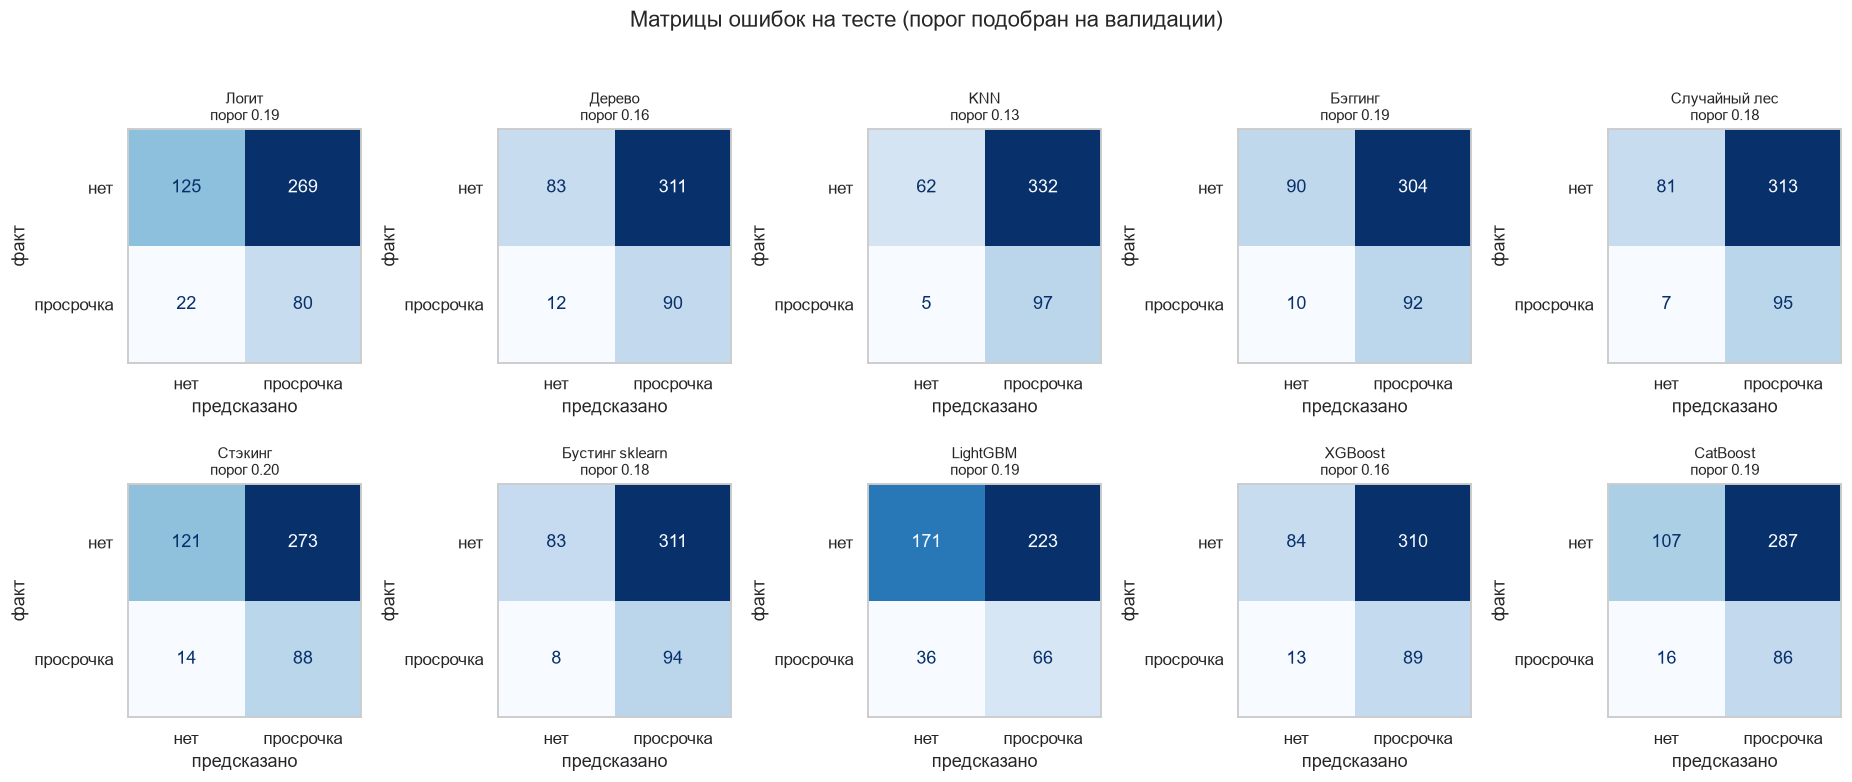

In [12]:
fig, axes = plt.subplots(2, 5, figsize=(17, 7))
for ax, name in zip(axes.ravel(), all_models):
    pred = (test_scores[name] >= chosen_thr[name]).astype(int)
    cm = confusion_matrix(y_test, pred, labels=[0, 1])
    ConfusionMatrixDisplay(cm, display_labels=["нет", "просрочка"]).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d"
    )
    ax.set_title(f"{name}\nпорог {chosen_thr[name]:.2f}", fontsize=10)
    ax.grid(False)
    ax.set_xlabel("предсказано")
    ax.set_ylabel("факт")
plt.suptitle("Матрицы ошибок на тесте (порог подобран на валидации)", y=1.02)
plt.tight_layout()
plt.show()

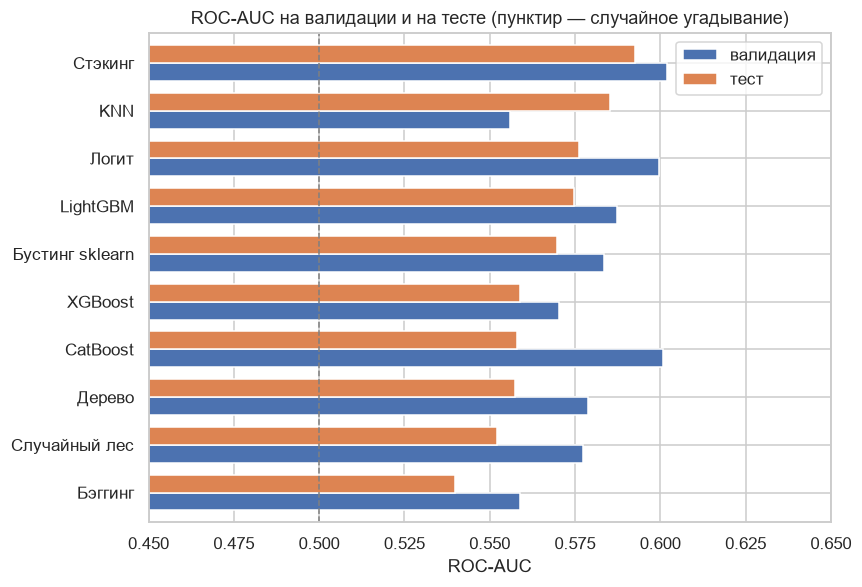

In [13]:
cmp = pd.DataFrame({
    "валидация": val_table.set_index("модель")["ROC-AUC"],
    "тест": test_table.set_index("модель")["ROC-AUC"],
}).sort_values("тест")

ax = cmp.plot.barh(figsize=(8, 5.5), width=0.75)
ax.axvline(0.5, color="gray", ls="--", lw=1)
ax.set_xlim(0.45, 0.65)
ax.set_xlabel("ROC-AUC")
ax.set_ylabel("")
ax.set_title("ROC-AUC на валидации и на тесте (пунктир — случайное угадывание)")
plt.tight_layout()
plt.show()

## 9. Выводы

**Качество.**  
Все модели слабые: ROC-AUC на тесте от 0.540 (бэггинг) до 0.593 (стэкинг). В тесте 496 кредитов, просрочка у 102 из них; стандартная ошибка ROC-AUC около 0.03, поэтому различия порядка 0.01–0.03 неотличимы от шума. Это та же картина, что у логистической регрессии, KNN, SVM и дерева в прошлых домашках: признаки, известные при выдаче, плохо отделяют просрочку.

**Кто лучше.**  
И на валидации (0.602), и на тесте (0.593) лучший — стэкинг. На тесте дальше идут KNN (0.585) и логит (0.576). Логит на третьем месте, ниже лучшей модели на 0.017. На валидации тройка лидеров почти неразличима: стэкинг (0.602), CatBoost (0.601), логит (0.600).

**Ансамбли против одиночных.**  
Лучший ансамбль — стэкинг (0.593), лучшая одиночная модель — KNN (0.585). Разница 0.008 при стандартной ошибке около 0.03 лежит в пределах шума. Формально стэкинг лучше, но преимущество ансамблей над одиночными моделями на этих данных не доказано. Остальные ансамбли (лес 0.552, бэггинг 0.540, бустинги 0.558–0.575) на тесте не превзошли логит (0.576).

**Валидация и тест.**  
ROC-AUC снизился при переходе с валидации на тест у 9 из 10 моделей, и не только у бустингов: у логита с 0.600 до 0.576, у случайного леса с 0.577 до 0.552, у дерева с 0.579 до 0.557, у стэкинга с 0.602 до 0.593. Сильнее всего просел CatBoost: с 0.601 до 0.558. Вырос только KNN: с 0.556 до 0.585. При таком слабом сигнале порядок моделей на валидации и на тесте заметно различается, поэтому выбор лучшей модели по одной валидации ненадёжен.

**Порог и матрицы ошибок.**  
Порог подбирался для каждой модели по F1 на валидации, тест для этого не использовался; получились значения от 0.13 до 0.20. При стандартном пороге 0.5 модели почти никого не помечают (на тесте от 0 до 2 кредитов): вероятности просрочки лежат около доли класса, 21%. При выбранных порогах модели помечают от 289 до 429 кредитов из 496. Recall высокий (0.65–0.95), precision около 0.23 (0.22–0.24): на каждую верно найденную просрочку приходится чуть больше трёх ложных срабатываний. F1 на тесте от 0.338 до 0.380; правило «ставить 1 всем» даёт 0.341. Выше него F1 у девяти моделей из десяти, у LightGBM (0.338) чуть ниже. Выигрыш небольшой. Accuracy при выбранных порогах 0.32–0.48 против 0.794 у правила «всем 0», поэтому по accuracy модели сравнивать нельзя.

**Практический смысл.**  
Ни одна модель не даёт надёжного скоринга: лучший ROC-AUC 0.593, а чтобы поймать большую часть просрочек, приходится помечать большую часть кредитов. Стэкинг формально лучший, но его прирост (0.008 к KNN и 0.017 к логиту) лежит в пределах шума, а сама модель заметно сложнее: три базовые модели, мета-модель и подбор параметров. Выбор между этими вариантами определяется не результатом теста, а требованиями к простоте и объяснимости модели.